# Physics 129 — Fall 2026

## Homework 8: $e^+e^-$ collision and jets

**Due Friday, November 6, 2026 at 11:59 p.m. Pacific Time**

**Late submissions accepted until Sunday, November 8, 2026 at 11:59 p.m. Pacific Time.**

**Total: 100 points. Each of parts (a)–(e) is worth 20 points.**

**Name:**  
**Student ID:**


## Submission instructions

Complete this notebook in Jupyter or another preferred platform. Place each answer adjacent to its question. Answer non-programmatic questions in Markdown with formatted formulas, or include clear scans of handwritten work.

Combine all work into **one PDF** for submission to Gradescope. Include the required AI-use disclosure at the end of the notebook.


## Collision energy and event displays

The three CSV files below each list the final-state particles from one simulated
$e^+e^-$ collision.

- **Event A:** [event_A.csv](event_A.csv)
- **Event B:** [event_B.csv](event_B.csv)
- **Event C:** [event_C.csv](event_C.csv)

Each row represents one particle. The columns are:

| Column | Meaning |
|:--|:--|
| `particle` | Particle number within this event |
| `pid` | PDG particle identification code |
| `charge` | Electric charge in units of the positron charge |
| `px`, `py`, `pz` | Three-momentum components, in GeV/$c$ |
| `E` | Total particle energy, in GeV |
| `m` | Particle mass, in GeV/$c^2$ |

### (a) Determine the collision energy (20 points)

**Determine the center-of-mass energy $\sqrt{s}$ of each $e^+e^-$ collision.**
Show your calculation and quote your answers in GeV.

The cell below loads the three events. For example, `events['A']['px']` gives
the $x$ components of the particle momenta in Event A. Keep the three CSV files
in the same folder as this notebook when copying or downloading the assignment.

In [ ]:
from pathlib import Path
import numpy as np

event_files = {label: Path(f'event_{label}.csv')
               for label in ('A', 'B', 'C')}
events = {label: np.genfromtxt(path, delimiter=',', names=True,
                              dtype=None, encoding='utf-8')
          for label, path in event_files.items()}
for label, particles in events.items():
    print(f'Event {label}: {len(particles)} particles')

In [ ]:
# Your calculations for part (a).

### Your results

| Event | Center-of-mass energy [GeV] |
|:--|:--|
| A | |
| B | |
| C | |

**Your calculation and explanation:**

### (b) Lego plots in pseudorapidity and azimuth (20 points)

For **each of Events A, B, and C**, make a three-dimensional lego plot with
pseudorapidity $\eta$ and azimuthal angle $\phi$ on the two horizontal axes.
Draw **one vertical bar per particle**, positioned at that particle's
$(\eta,\phi)$, with height equal to its **energy $E$ in GeV**.
Use the same bar width for all particles.

Label all three axes and identify the event in each plot title.

**Illustrative example only:** The plot below uses invented dummy data. It is not from Event A, B, or C.

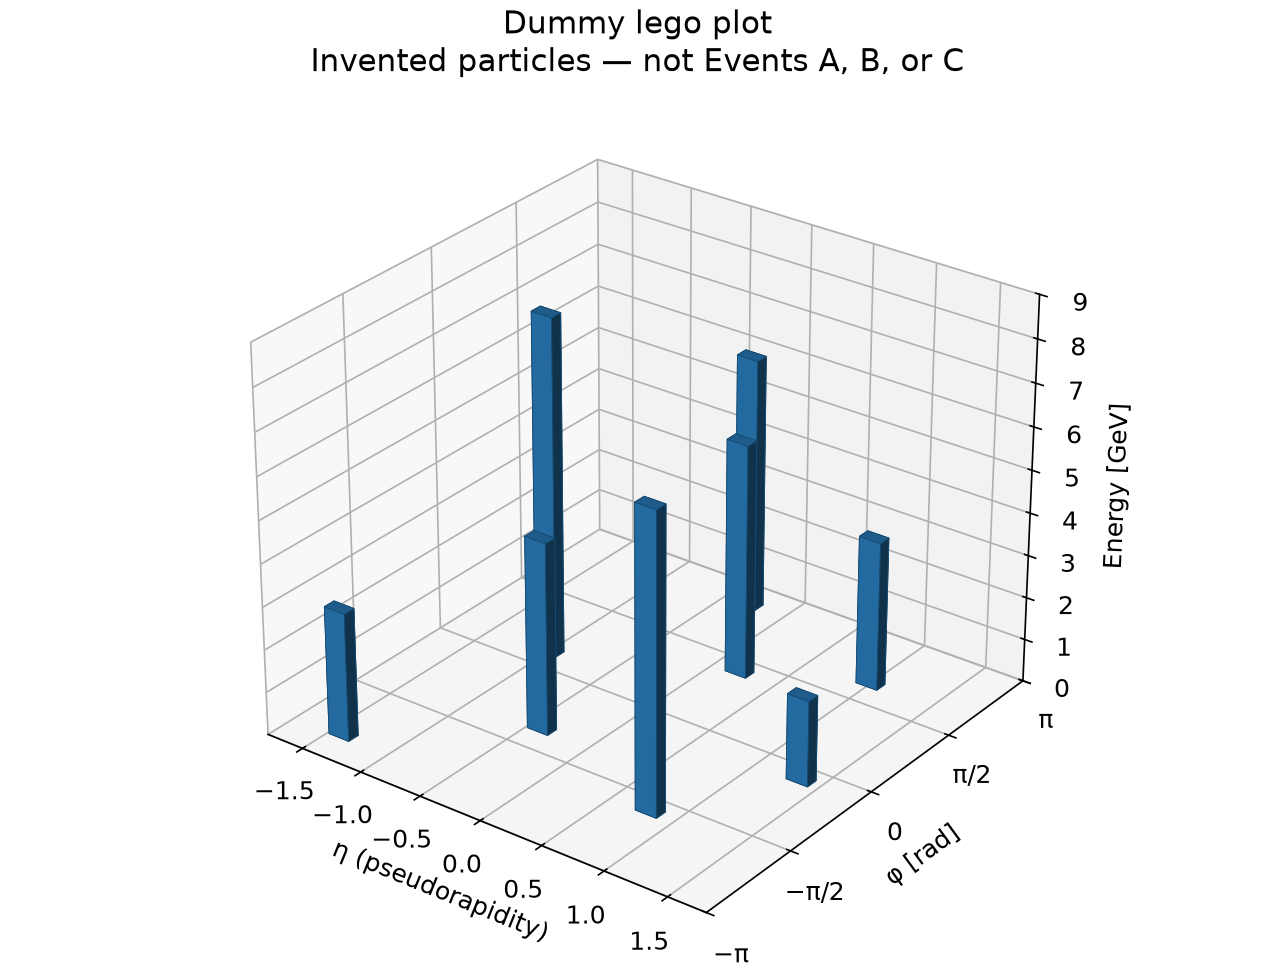


In [ ]:
# Your lego plots for Events A, B, and C.


### (c) Transverse views of the events (20 points)

For **each of Events A, B, and C**, draw a cross-sectional view in the $x$-$y$
plane, looking along the beam axis. Place the collision point at the origin
and draw an arrow from the origin in the transverse direction of each particle,
as determined by $(p_x,p_y)$.

Use **the same arrow length for every particle**: this plot should show only
the directions. Do not encode energy or momentum magnitude in the arrow length,
width, or color. These arrows represent directions, not particle trajectories.

Use equal scales on the $x$ and $y$ axes, label the axes as direction coordinates
in arbitrary units, and identify the event in each plot title.

**Illustrative example only:** The plot below uses invented dummy data. It is not from Event A, B, or C.

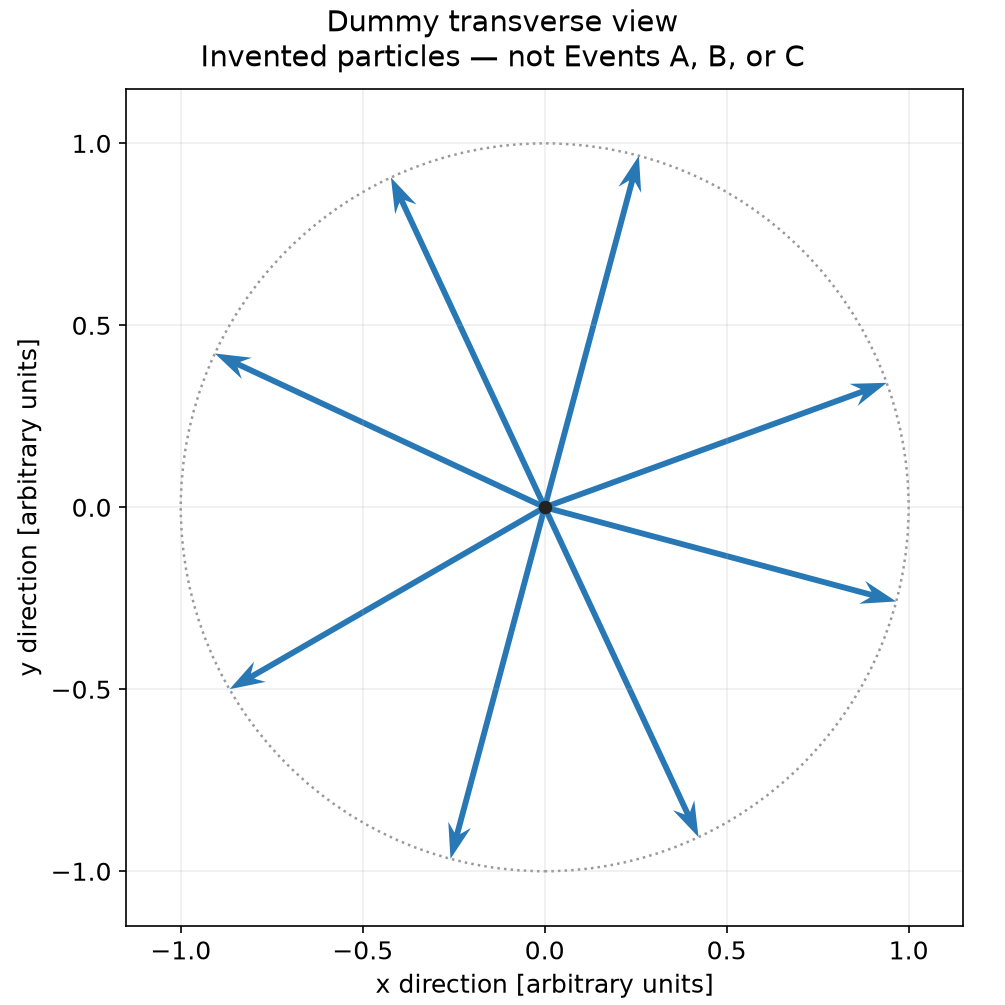


In [ ]:
# Your transverse direction plots for Events A, B, and C.


## Jet reconstruction

Use **Event B and Event C** from the event files above to reconstruct jets with
$\epsilon=0.1$ and $\delta=30^\circ$. Work in the event's center-of-mass frame
and use the full three-dimensional particle momenta.

For this exercise, use the **iterative cone construction** described below,
based on the Sterman–Weinberg cone idea. Here $\delta$ is the cone half-angle
and $\epsilon$ sets the minimum jet energy as a fraction of the original event
energy. This prescription constructs individual jets. The original
[Sterman–Weinberg definition](https://doi.org/10.1103/PhysRevLett.39.1436)
instead classifies two-jet events by the fraction of energy outside two cones.

### (d) Reconstruct the jets and report their kinematics (20 points)

Implement the following procedure and apply it separately to Events B and C:

1. Calculate the total event energy $E_{\mathrm{event}}$ from all particles.
   Keep this value fixed throughout the clustering.
2. Use each remaining particle direction as a seed for a cone of half-angle
   $30^\circ$. Include a particle if the opening angle between its momentum and
   the cone axis is at most $30^\circ$.
3. For each seed, update the cone axis to the direction of the vector sum of
   the momenta inside it. Recalculate membership and repeat until the set of
   particles in the cone no longer changes. This gives a stable cone.
4. Among the stable cones, choose the one with the largest summed particle
   energy. If its energy is at least $0.1E_{\mathrm{event}}$, accept it as a jet
   and remove its particles from further clustering. If two cones have exactly
   equal energy, choose the one found first in CSV particle order.
5. Repeat steps 2–4 on the remaining particles. Stop when no particles remain
   or the most energetic remaining stable cone has energy below
   $0.1E_{\mathrm{event}}$. Leave any remaining particles unclustered.

Use the true three-dimensional opening angle, rather than a distance in the
$\eta$–$\phi$ plane. Do not force a particular number of jets or assign a
particle to more than one jet. The stopping rule does not require the total
unclustered energy to be less than $0.1E_{\mathrm{event}}$.

For each accepted jet, obtain its four-momentum by summing the four-momenta of
its constituent particles:

$$P_J^\mu=\sum_{i\in J}p_i^\mu.$$

For each event, **report the number of reconstructed jets and each jet's
$p_T$, $\eta$, and $\phi$**. Present the jet kinematics in a table with one row
per jet, identifying the event and jet number. Express $p_T$ in GeV/$c$ and
$\phi$ in radians; $\eta$ is dimensionless. Number the jets in decreasing
order of energy.

| Event | Jet | $p_T$ [GeV/$c$] | $\eta$ | $\phi$ [rad] |
|:--|:--|:--|:--|:--|
| | | | | |

In [ ]:
# Reconstruct jets in Events B and C; report the counts and tabulate pT, eta, and phi.


### (e) Invariant mass of the combined jet system (20 points)

For each event separately, combine **all reconstructed jets into a single
system** and calculate its invariant mass. Obtain the system's four-momentum
by adding the jet four-momenta, and show how you calculate the mass from it.
Do not add the individual jet masses or include the unclustered particles.

Quote the combined invariant mass for Event B and for Event C in GeV/$c^2$.

For each event, explain how the invariant mass of the combined jet system
relates to the center-of-mass energy you calculated in part (a). Are they
equal? Explain your result.

| Event | Invariant mass of all reconstructed jets [GeV/$c^2$] |
|:--|:--|
| B | |
| C | |

**Your calculation and explanation:**

In [ ]:
# Calculate the invariant mass of the combined jet system for each event.

## Required AI-use disclosure

Artificial intelligence tools may be used to support your learning and to prepare this homework submission. Regardless of whether you use AI, you are fully responsible for everything you submit and must be able to explain your work without AI assistance when asked by the instructor.

Include one disclosure covering your work on the **entire homework**:

- If you **did not use AI**, state: “I did not use AI technology to complete this homework.”
- If you **used AI**, identify every platform or software tool used and include the exact prompts you entered. You may also briefly describe how you used the output.

A submission without an AI-use disclosure, or one that acknowledges AI use but omits the platform/software or prompts, will be returned without being graded.

**Your disclosure:**
